# Ejercicio 1 — Encoders: ResNet18

Inferencia ImageNet e inspección de activaciones intermedias. No se entrena el modelo. Se reutilizan la imagen y los pesos oficiales locales; si faltan, se descargan.

In [1]:
from pathlib import Path
import os

# Compatible con ejecución desde la raíz del proyecto o desde esta carpeta.
cwd = Path.cwd().resolve()
BASE = cwd if cwd.name == "01_encoders" else (cwd / "01_encoders" if (cwd / "01_encoders").is_dir() else cwd / "ejercicios" / "01_encoders")
if not BASE.is_dir():
    raise RuntimeError("Abre el notebook desde la raíz del proyecto o desde ejercicios/01_encoders/.")
DATA = BASE / "data"
DATA.mkdir(parents=True, exist_ok=True)
os.environ["TORCH_HOME"] = str(DATA / "torch_cache")

import torch
import torchvision
from torchvision.models import resnet18, ResNet18_Weights
from PIL import Image, UnidentifiedImageError
import matplotlib.pyplot as plt

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"PyTorch: {torch.__version__}; torchvision: {torchvision.__version__}")
print(f"Dispositivo: {device}; CUDA disponible: {torch.cuda.is_available()}")
if device.type == "cuda":
    print(f"GPU: {torch.cuda.get_device_name(0)}")

PyTorch: 2.11.0+cu128; torchvision: 0.26.0+cu128
Dispositivo: cuda; CUDA disponible: True
GPU: NVIDIA GeForce RTX 2060 with Max-Q Design


## A. Imagen e inferencia directa

Imagen de ejemplo del repositorio oficial de PyTorch. `weights.transforms()` aplica el resize, recorte central y normalización que corresponden a los pesos seleccionados. Las probabilidades softmax indican confianza del modelo, no certeza calibrada.

URL original: https://raw.githubusercontent.com/pytorch/hub/master/images/dog.jpg


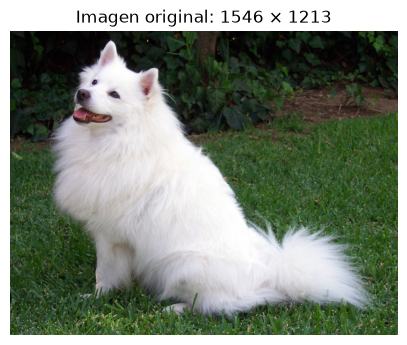

In [2]:
from urllib.request import Request, urlopen
from urllib.error import URLError

IMAGE_URL = "https://raw.githubusercontent.com/pytorch/hub/master/images/dog.jpg"
image_path = DATA / "dog.jpg"
print("URL original:", IMAGE_URL)
if not image_path.exists():
    try:
        request = Request(IMAGE_URL, headers={"User-Agent": "vision-examen/1.0"})
        with urlopen(request, timeout=30) as response:
            content = response.read()
        # Comprobar antes de guardar para no conservar una descarga inválida.
        from io import BytesIO
        with Image.open(BytesIO(content)) as check:
            check.verify()
        image_path.write_bytes(content)
    except (URLError, TimeoutError, OSError, ValueError) as exc:
        raise RuntimeError(f"No se pudo descargar una imagen válida de {IMAGE_URL}: {exc}") from exc
try:
    with Image.open(image_path) as im:
        image = im.convert("RGB")
except (OSError, UnidentifiedImageError) as exc:
    raise RuntimeError(f"Imagen inválida en {image_path}. Elimínala y reintenta: {exc}") from exc

plt.figure(figsize=(5, 4))
plt.imshow(image)
plt.title(f"Imagen original: {image.width} × {image.height}")
plt.axis("off");
plt.show()

In [3]:
weights = ResNet18_Weights.DEFAULT
try:
    model = resnet18(weights=weights).to(device)
except (OSError, RuntimeError, URLError) as exc:
    raise RuntimeError(f"No se pudieron cargar o descargar los pesos de {weights.url}: {exc}") from exc
model.eval()
batch = weights.transforms()(image).unsqueeze(0).to(device)
print("Pesos:", weights, "| URL:", weights.url)
print("Tensor de entrada (N, C, H, W):", tuple(batch.shape))

Pesos: ResNet18_Weights.IMAGENET1K_V1 | URL: https://download.pytorch.org/models/resnet18-f37072fd.pth
Tensor de entrada (N, C, H, W): (1, 3, 224, 224)


## B. Hook en `layer3`

Se registra un hook de salida y se elimina con `finally`, incluso si falla la inferencia. En ResNet18, para una entrada 224 × 224, `layer3` produce 256 canales de 14 × 14; el clasificador produce 1000 logits. Las activaciones son respuestas intermedias, no segmentaciones ni explicaciones causales.

In [4]:
activations = {}
def capture_layer3(module, inputs, output):
    activations["layer3"] = output.detach().cpu()

hook = model.layer3.register_forward_hook(capture_layer3)
try:
    with torch.inference_mode():
        logits = model(batch)
        probabilities = logits.softmax(dim=1)
        probability, index = probabilities[0].max(dim=0)
finally:
    hook.remove()

feature_maps = activations["layer3"]
print(f"Clase dominante: {weights.meta['categories'][index.item()]}")
print(f"Probabilidad softmax: {probability.item():.2%}")
print("Salida layer3 (N, C, H, W):", tuple(feature_maps.shape))
print("Logits finales (N, clases):", tuple(logits.shape))
assert feature_maps.shape == (1, 256, 14, 14)
assert logits.shape == (1, 1000)
assert hook.id not in model.layer3._forward_hooks
print("Hook eliminado correctamente.")

Clase dominante: Samoyed
Probabilidad softmax: 88.46%
Salida layer3 (N, C, H, W): (1, 256, 14, 14)
Logits finales (N, clases): (1, 1000)
Hook eliminado correctamente.


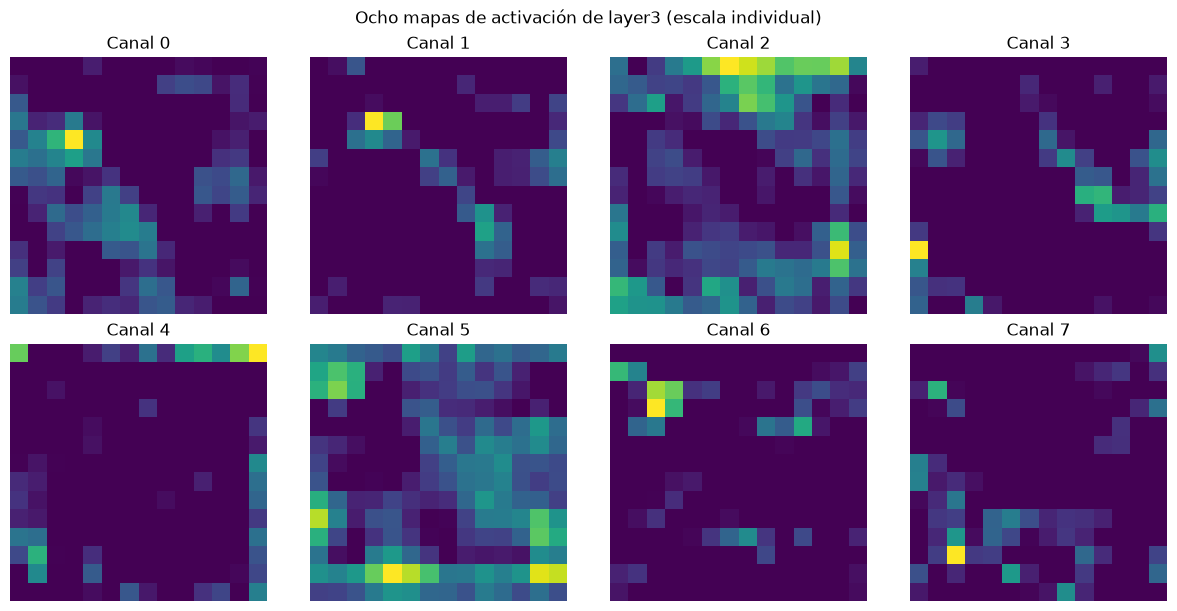

In [5]:
fig, axes = plt.subplots(2, 4, figsize=(12, 6), constrained_layout=True)
for channel, ax in enumerate(axes.flat):
    ax.imshow(feature_maps[0, channel].numpy(), cmap="viridis")
    ax.set_title(f"Canal {channel}")
    ax.axis("off")
fig.suptitle("Ocho mapas de activación de layer3 (escala individual)")
plt.show()

### Interpretación de dimensiones

- La imagen RGB se transforma en `(1, 3, 224, 224)`: lote de una imagen, tres canales y tamaño espacial 224 × 224.
- `layer3` devuelve `(1, 256, 14, 14)`: 256 mapas espaciales. La reducción espacial procede de los strides de la red.
- La salida `(1, 1000)` contiene un logit por clase ImageNet. Softmax los convierte en probabilidades que suman 1.
- Cada mapa se representa con escala de color independiente; los colores no permiten comparar magnitudes absolutas entre canales.